# 05 — Aspects (Phase 3 ส่วนที่ 1): keyword vs zero-shot และเตรียมชุด label

**โจทย์:** บอกว่ารีวิว **ชม/ติเรื่องอะไร** ใน 4 aspect: อาหาร/รสชาติ, ราคา/ความคุ้มค่า, บริการ, บรรยากาศ/สถานที่

**ทำไมต้องทำระดับประโยค:** จาก 01 รีวิว Wongnai ยาวราว 90 คำ และมักชมเรื่องหนึ่งแต่ติอีกเรื่อง
ถ้าให้หนึ่ง label ต่อรีวิว จะบอกไม่ได้ว่า "ลบ" นั้นเป็นเรื่องอาหารหรือเรื่องบริการ จึงแยกรีวิวเป็นประโยคก่อน

**แผน Phase 3**
1. *(notebook นี้)* ทำ 2 วิธีที่ไม่ต้องใช้ label: **keyword** และ **zero-shot ด้วย embedding** แล้วสร้างไฟล์ 400 ประโยคให้ label เอง
2. *(notebook ถัดไป หลัง label เสร็จ)* วัดว่าวิธีไหนแม่นกว่า แล้วเทรน classifier จาก label จริง
3. topic modeling / association rules

ทำไมต้อง label เอง: ตอนนี้เราไม่มีทางรู้เลยว่า keyword หรือ zero-shot แม่นแค่ไหน
ทุกตัวเลขใน notebook นี้คือ **"โมเดลบอกว่า"** ไม่ใช่ **"ความจริง"**

In [1]:
import sys, re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data.load import load_wongnai
from src.aspects import ASPECTS, ASPECT_NAMES_TH, ASPECT_KEYWORDS, detect_aspects, split_sentences
from src.viz import use_thai_font

FIGS = ROOT / "reports" / "figures"
INTERIM = ROOT / "data" / "interim"
LABELS = ROOT / "data" / "labels"
INTERIM.mkdir(parents=True, exist_ok=True)
LABELS.mkdir(parents=True, exist_ok=True)
use_thai_font()

'Thonburi'

## 1. สุ่มรีวิว

สุ่ม **ดาวละ 400 รีวิว** จาก train (2,000 รีวิว) แทนที่จะใช้ทั้งหมด เพราะสองเหตุผล:
- embedding ด้วย bge-m3 บน CPU ใช้ ~14 ms ต่อประโยค ทั้ง dataset (~600k ประโยค) จะกินเวลาหลายชั่วโมง
- ถ้าสุ่มตามสัดส่วนจริง จะได้รีวิวลบแค่ ~6% แต่ aspect ที่ถูก **ติ** คือส่วนที่มีค่าที่สุด การสุ่มเท่ากันทุกดาวทำให้มีประโยคลบพอให้ label

ข้อแลกเปลี่ยน: ตัวเลขสัดส่วนใน notebook นี้ **ไม่ใช่สัดส่วนจริงของ Wongnai** เพราะเราจงใจสุ่มรีวิวลบมากเกินจริง

In [2]:
wn = load_wongnai(["train"]).drop_duplicates("text")
reviews = (wn.groupby("label_raw", group_keys=False)
             .apply(lambda g: g.sample(min(len(g), 400), random_state=0), include_groups=False)
             .assign(stars=lambda d: wn.loc[d.index, "label_raw"])
             .reset_index(names="review_id"))
reviews.stars.value_counts().sort_index()

/Users/riewta/Downloads/mlproj/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


stars
1    400
2    400
3    400
4    400
5    400
Name: count, dtype: int64

## 2. แยกประโยค

ภาษาไทยไม่มีจุดฟูลสต็อป การแยกประโยคเลยยากกว่าภาษาอังกฤษ ลองมาสองวิธีก่อนเขียน notebook นี้:
- `whitespace`: ตัดทุกเว้นวรรค ละเอียดเกินไปจนประโยคขาดความหมาย ("เพราะดันขับเลยร้านอื่นๆ" | "ที่เค้ารู้จักไปแล้ว")
- `crfcut` (โมเดล CRF ที่เทรนจากภาษาไทย): ตัดเป็นอนุประโยคได้ดี แต่ **รวมข้ามย่อหน้า** ("...มั้ย\n\nหมูจุ่ม...")

→ `split_sentences()` ใน `src/aspects.py` ตัดที่ขึ้นบรรทัดใหม่ก่อน แล้วค่อยใช้ crfcut ในแต่ละย่อหน้า

In [3]:
example = reviews.text[reviews.stars == 2].iloc[0]
print(example[:300], "\n")
for s in split_sentences(example)[:8]:
    print("•", s)

เมื่อวานตั้งใจจะมาทานแต่ร้านปิด เปลี่ยนไปทานข้าวต้มขาไก่ มื้อกลางวัน วันนี้เลยขับรถมาทานตั้งแต่ 11โมง พอมีที่จอดรถได้ข้างร้านพอดีค่ะ

ต้องบอกว่า ร้านกว้าง 7 คูหา ใหญ่มากทีเดียวแบ่งโซนที่นั่งมีทั้งในและนอกห้องแอร์ (ห้องแอร์คิดค่าหัวเพิ่มอีก 10฿/คน) นั่งด้านนอกก็มีพัดลมพอคลายร้อนได้บ้าง แต่พนักงานน้อย 



• เมื่อวานตั้งใจจะมาทานแต่ร้านปิด
• เปลี่ยนไปทานข้าวต้มขาไก่ มื้อกลางวัน
• วันนี้เลยขับรถมาทานตั้งแต่ 11โมง พอมีที่จอดรถได้ข้างร้านพอดีค่ะ
• ต้องบอกว่า ร้านกว้าง 7 คูหา ใหญ่มากทีเดียวแบ่งโซนที่นั่งมีทั้งในและนอกห้องแอร์ (ห้องแอร์คิดค่าหัวเพิ่มอีก 10฿/คน) นั่งด้านนอกก็มีพัดลมพอคลายร้อนได้บ้าง แต่พนักงานน้อยค่ะ รอนานกว่าจะมีคนมารับออเดอร์
• ทั้งๆที่ร้านพึ่งเปิดยังไม่ค่อยมีลูกค้า
• สั่งอาหารไป รออาหารไม่นานค่ะ
• จะช้าก็เมนูปากหม้อญวนใช้เวลาทำนานหน่อย
• - แหนมเนือง


In [4]:
sents = (reviews.assign(sentence=reviews.text.map(split_sentences))
                .explode("sentence")[["review_id", "stars", "sentence"]]
                .reset_index(drop=True))
sents["pos"] = sents.groupby("review_id").cumcount()
sents = sents[sents.sentence.str.len() >= 5].reset_index(drop=True)
print(f"{len(reviews):,} reviews -> {len(sents):,} sentences ({len(sents) / len(reviews):.1f} per review)")
sents.sentence.str.len().describe().round()

2,000 reviews -> 29,286 sentences (14.6 per review)


count    29286.0
mean        36.0
std         31.0
min          5.0
25%         16.0
50%         27.0
75%         46.0
max        500.0
Name: sentence, dtype: float64

**สิ่งที่เจอ:** ส่วนใหญ่ตัดได้ดี แต่บางประโยคยังยาวและมีหลายเรื่อง เช่น ประโยคที่ 4 ข้างบนพูดถึงทั้งที่นั่ง แอร์ ราคาห้องแอร์ และพนักงาน
**→ การตัดสินใจ:** label แบบ **multi-label** (หนึ่งประโยคมีได้หลาย aspect) แทนที่จะบังคับเลือกหนึ่ง aspect

## 3. Keyword baseline

`detect_aspects()` เทียบคำหลังตัดคำ (token) กับรายการ keyword ของแต่ละ aspect

In [5]:
kw = pd.DataFrame([detect_aspects(s) for s in sents.sentence])
sents[[f"kw_{a}" for a in ASPECTS]] = kw.values
sents["kw_any"] = kw.any(axis=1)

summary = pd.DataFrame({
    "sentences": kw.mean(),
    "reviews": sents.groupby("review_id")[[f"kw_{a}" for a in ASPECTS]].max().mean().values,
}).rename(index=ASPECT_NAMES_TH)
print(f"sentences with no aspect keyword: {1 - sents.kw_any.mean():.0%}")
summary.style.format("{:.0%}")

sentences with no aspect keyword: 61%


,sentences,reviews
อาหาร/รสชาติ,21%,88%
ราคา/ความคุ้มค่า,8%,58%
บริการ,7%,51%
บรรยากาศ/สถานที่,6%,48%


ในระดับรีวิว อาหารถูกพูดถึง 88% ของรีวิว ส่วนบริการและบรรยากาศราวครึ่งหนึ่ง
แต่ในระดับประโยค **61% ไม่ติด keyword เลย** ซึ่งเป็นเรื่องปกติ เพราะหลายประโยคเป็นการเล่าเรื่อง ("เมื่อวานตั้งใจจะมาทาน")

**ทำไมเทียบ token ไม่ใช่ substring?** ลองนับทั้งสองแบบ:

In [6]:
def substring_hits(texts, words):
    return sum(any(w in t for w in words) for t in texts)

sample = sents.sentence.sample(5000, random_state=0)
cmp = pd.DataFrame({
    "token match": [sum(detect_aspects(s)[a] for s in sample) for a in ASPECTS],
    "substring match": [substring_hits(sample, ASPECT_KEYWORDS[a]) for a in ASPECTS],
}, index=[ASPECT_NAMES_TH[a] for a in ASPECTS])
cmp

,token match,substring match
อาหาร/รสชาติ,1070,1214
ราคา/ความคุ้มค่า,405,456
บริการ,353,542
บรรยากาศ/สถานที่,263,305


substring match เจอ "บริการ" มากกว่าราว 1.5 เท่า (542 vs 353) ดูว่าส่วนที่เกินมาคืออะไร:

In [7]:
only_sub = [s for s in sample if any(w in s for w in ASPECT_KEYWORDS["service"]) and not detect_aspects(s)["service"]]
for s in only_sub[:6]:
    print("•", s[:120])

• ไส้กรอกปลาแบบพวก 2 ไม้ 10 อีกไม่กี่ชิ้น
• กรอบนอกนุ่มใน
• อาหารอย่างอื่นก็ปกติครับ
• ร้านอาหารอิตาเลียนสุดหรูอยู่ในโรงแรมเชอราตันแกรนด์สุขุมวิท
• แต่ตูยังไม่รู้รดชาด เพราะได้แดกแต่ไส้กรอกกะตำหมูยอแค่นั้น!
• แอ๊ปเปิ้ลครัมเบิ้ล เค้กช๊อคโกแล๊ต เค้กแครอท ชีสเค้กบราวนี่  มัฟฟินต่างๆ บราวนี่ ครัวซองค์


**สิ่งที่เจอ: substring ผิดในแบบที่ไม่มีใครตั้งใจ**
- "รอ" (รอนาน) ไปโผล่ใน **"กรอก"** (ไส้กรอก), **"กรอบ"** (กรอบนอกนุ่มใน), **"แครอท"** และแม้แต่ **ข้ามคำ**: "อาหา**ร อ**ย่างอื่น"
- ตอนเลือก keyword เจอแบบเดียวกัน: "ช้า" อยู่ใน **"ช้าง"**, "ถูก" อยู่ใน **"ถูกใจ"**, "บาท" อยู่ใน **"บทบาท"**

แต่ token match ก็มีจุดอ่อนของตัวเอง ซึ่งเจอจากการไล่ดูคำในข้อมูลจริง แล้วแก้ใน `src/aspects.py`:
- **คำประสมในพจนานุกรม:** "ราคาแพง", "เจ้าของร้าน", "ถูกปาก" เป็นคำเดียว ไม่ match "แพง"/"เจ้าของ"/"ถูก" → เพิ่มคำประสมที่เจอบ่อยเข้าไปในรายการ
- **คำสะกดผิด:** "เสริฟ" (ที่ถูกคือ "เสิร์ฟ") ถูกตัดเป็นเศษ "เส", "ริ", "ฟ" จึงไม่ match อะไรเลย → แก้คำสะกดผิดที่พบบ่อยก่อนตัดคำ ("เสริฟ", "รสชาด")
- **คำที่มีความหมายตามบริบท:** "เยอะ" ส่วนใหญ่คือ "คนเยอะ" ไม่ใช่ "ให้เยอะ" (คำก่อนหน้า "เยอะ" คือ "คน" 122 ครั้ง เทียบกับ "ให้" 49) → จับเป็นวลีสองคำ ("ให้ เยอะ") แทนคำเดี่ยว แบบเดียวกับ "เสิร์ฟ เร็ว"
- **ข้อจำกัดที่ยังแก้ไม่ได้:** "ถูกปากมาก" ถูกตัดเป็น "ถูก" + "ปากมาก" (ช่างพูด) ตัวตัดคำเลือกผิดเอง

เป็น trade-off ที่ไม่มีคำตอบสมบูรณ์ เลือก token เพราะผิดน้อยกว่าและแก้เป็นจุดๆ ได้

## 4. Zero-shot ด้วย sentence embedding

**ไอเดีย:** แปลงทุกประโยคเป็น vector ที่ประโยคความหมายใกล้กันจะอยู่ใกล้กัน
แล้วเขียน "ประโยคต้นแบบ" ของแต่ละ aspect ("ราคาแพง ไม่คุ้ม", "พนักงานบริการดี") ประโยคไหนใกล้ต้นแบบของ aspect ไหน ก็น่าจะพูดเรื่องนั้น
ข้อดีคือ **ไม่ต้องมี keyword** จึงจับ "ไอศกรีมก็เริ่ด" ได้ แม้ไม่มีคำว่าอร่อย

**เลือกโมเดล:** ลองสามตัวกับประโยคทดสอบ 10 ประโยคก่อนเขียน notebook นี้
- `multilingual-e5-small/base` ให้คะแนนทุก aspect อัดกันที่ 0.80–0.94 แยกไม่ออก และ e5-base ทาย "แอร์ไม่เย็น ร้อน" เป็นเรื่องอาหาร
- **`BAAI/bge-m3`** คะแนนกระจาย (0.48–0.81) ทาย aspect อันดับหนึ่งถูกทั้ง 8 ประโยคที่มี aspect และประโยคที่ไม่มี aspect ได้คะแนนต่ำ → เลือกตัวนี้ แลกกับความช้ากว่า (~14 ms/ประโยคบน CPU)

embedding ถูก cache ไว้ใน `data/interim/` และจะใช้ซ้ำตอนทำ topic modeling

In [8]:
from sentence_transformers import SentenceTransformer
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
encoder = SentenceTransformer("BAAI/bge-m3", device=DEVICE)

cache = INTERIM / f"bge_m3_{len(sents)}.npy"
if cache.exists():
    emb = np.load(cache)
else:
    emb = encoder.encode(sents.sentence.tolist(), batch_size=32, normalize_embeddings=True, show_progress_bar=False)
    np.save(cache, emb)
emb.shape

W1128 02:07:10.484000 58431 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 37269.57it/s]

(29286, 1024)

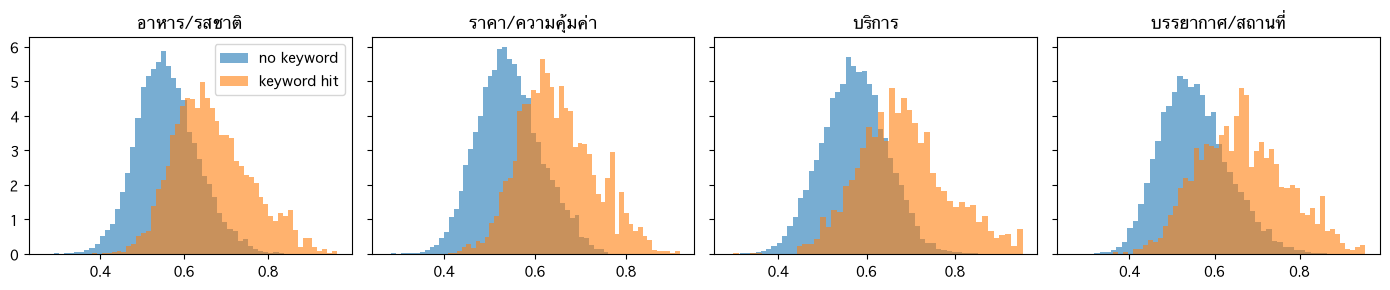

In [9]:
PROTOTYPES = {
    "taste":    ["อาหารอร่อย รสชาติดี", "รสชาติแย่ จืด ไม่อร่อย", "เนื้อนุ่ม หอม กลมกล่อม", "อาหารไม่สด มีกลิ่นคาว"],
    "price":    ["ราคาถูก คุ้มค่า", "ราคาแพง ไม่คุ้ม", "ปริมาณเยอะ คุ้มกับเงิน", "ราคาจานละ 200 บาท"],
    "service":  ["พนักงานบริการดี สุภาพ", "บริการแย่ พนักงานไม่สนใจ", "รออาหารนานมาก เสิร์ฟช้า", "เจ้าของร้านใจดี ต้อนรับอย่างดี"],
    "ambience": ["ร้านบรรยากาศดี ตกแต่งสวย", "ร้านสกปรก ร้อน เสียงดัง", "ที่นั่งสบาย แอร์เย็น", "วิวสวย เหมาะกับถ่ายรูป"],
}
proto = {a: encoder.encode(p, normalize_embeddings=True) for a, p in PROTOTYPES.items()}
for a in ASPECTS:
    sents[f"zs_{a}"] = (emb @ proto[a].T).max(axis=1)

fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, a in zip(axes, ASPECTS):
    ax.hist(sents.loc[sents[f"kw_{a}"] == 0, f"zs_{a}"], bins=50, alpha=0.6, density=True, label="no keyword")
    ax.hist(sents.loc[sents[f"kw_{a}"] == 1, f"zs_{a}"], bins=50, alpha=0.6, density=True, label="keyword hit")
    ax.set_title(ASPECT_NAMES_TH[a])
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGS / "aspects_zeroshot_vs_keyword.png", dpi=120)

คะแนนของประโยคที่ติด keyword สูงกว่าที่ไม่ติดชัดเจน แปลว่าสองวิธีจับสัญญาณเดียวกันอยู่บ้าง แต่ทับกันมาก
ลองดูตัวอย่างประโยคตามช่วงคะแนน (top 3%, 3–10%, 10–50%):

In [10]:
def show_band(aspect, lo, hi, n=5):
    band = sents[(sents[f"zs_{aspect}"] >= lo) & (sents[f"zs_{aspect}"] < hi)]
    print(f"-- {ASPECT_NAMES_TH[aspect]}  score {lo:.2f}–{hi:.2f}  ({len(band):,} sentences)")
    for _, r in band.sample(min(n, len(band)), random_state=0).iterrows():
        print(f"  kw={r[f'kw_{aspect}']}  {r.sentence[:90]}")

for a in ["price", "ambience"]:
    q = sents[f"zs_{a}"].quantile([0.5, 0.9, 0.97]).values
    show_band(a, q[2], 1.0)
    show_band(a, q[1], q[2])
    show_band(a, q[0], q[1])

-- ราคา/ความคุ้มค่า  score 0.71–1.00  (879 sentences)
  kw=1  ราคาอาหารไม่ถูกไม่แพง
  kw=0  รสชาติดี
  kw=1  ราคาถูกมากก
  kw=1  ค่อนข้างแพงแต่ไม่อร่อย
  kw=1  ไม่เหมาะสมกับราคา
-- ราคา/ความคุ้มค่า  score 0.65–0.71  (2,050 sentences)
  kw=1  ลองมาดูราคาจริงจังก็ไม่แพงเท่าไหร่นะ
  kw=0  บรรยากาศดี
  kw=0  ร้านมีมุมต่างๆให้เลือกนั่ง คือดีอะแก รสชาตอาหารก็อร่อยดี
  kw=0  อร่อยมาก
  kw=0  หลากหลายมากก
-- ราคา/ความคุ้มค่า  score 0.55–0.65  (11,714 sentences)
  kw=0  กลิ่นคาวมาก.
  kw=0  เป็นร้านข้าวต้มที่โปรดปรานร้านนึง
  kw=1  น้ำปั่นราคาตั้งแต่ 35- 60 บาท
  kw=0  เก้าอี้ก็มีเบาะวางรองนั่งค่ะ
  kw=1  เป๊ปซี่ขวดละ 40 กว่าบาทแน่ะ
-- บรรยากาศ/สถานที่  score 0.74–1.00  (879 sentences)
  kw=1  ร้านค่อนข้างร้อน
  kw=1  ร้านโปร่ง ที่นั่งเยอะ กว้างขวาง
  kw=0  ดูแลเอาใจใส่ลูกค้าดีมากๆค่ะ
  kw=0  ร้านนี้คนเยอะพอสมควร
  kw=1  ถ่ายรูปสวยมากๆ
-- บรรยากาศ/สถานที่  score 0.67–0.74  (2,050 sentences)
  kw=0  ราคาอาหารของที่ร้านนี้ก็ไม่แพงมากครับ
  kw=0  เหมาะกับมานั่งคุยกับเพื่อนฝูง สบายๆ ร้านจัดแต่งแบบเ

**สิ่งที่เจอ: zero-shot สับสน aspect กับประโยคสั้นที่เป็นการประเมิน**
- ช่วงคะแนนสูงสุดของ "ราคา" มี **"รสชาติดี"** ปนอยู่ ช่วงถัดมามี "บรรยากาศดี", "อร่อยมาก"
- "ดูแลเอาใจใส่ลูกค้าดีมาก" (บริการ) ไปอยู่ช่วงสูงสุดของ "บรรยากาศ"
- ส่วน "น้ำปั่นราคาตั้งแต่ 35–60 บาท" ซึ่งพูดเรื่องราคาตรงๆ กลับได้คะแนนต่ำ

ตีความ: embedding จับได้แรงว่า **"นี่คือประโยคที่ชม/ติ"** แต่จับได้อ่อนกว่าว่า **"ชม/ติเรื่องอะไร"**
ไอเดียสำหรับส่วนที่ 2: ใช้คะแนน **เทียบกับ aspect อื่น** (เช่น คะแนน aspect นี้ ลบ คะแนนสูงสุดของ aspect อื่น) แทนคะแนนดิบ

ยังไม่มี label เลยตั้ง threshold ไม่ได้ ใช้ **top 10% ของแต่ละ aspect** เป็น "hit" ชั่วคราวเพื่อเทียบกับ keyword:

In [11]:
TOP = 0.10  # call the top 10% of scores per aspect a zero-shot "hit" (no labels yet to tune this)
for a in ASPECTS:
    sents[f"zshit_{a}"] = sents[f"zs_{a}"] >= sents[f"zs_{a}"].quantile(1 - TOP)

agree = pd.DataFrame({
    ASPECT_NAMES_TH[a]: pd.crosstab(sents[f"kw_{a}"], sents[f"zshit_{a}"]).stack()
    for a in ASPECTS
}).T
agree.columns = [f"kw={k} zs={'hit' if z else 'no'}" for k, z in agree.columns]
agree

,kw=0 zs=no,kw=0 zs=hit,kw=1 zs=no,kw=1 zs=hit
อาหาร/รสชาติ,22227,868,4130,2061
ราคา/ความคุ้มค่า,24988,1881,1369,1048
บริการ,25264,1928,1093,1001
บรรยากาศ/สถานที่,25432,2212,925,717


สองวิธี **เห็นตรงกันแค่บางส่วน** เช่น อาหาร: keyword เจอ 6,191 ประโยค zero-shot เจอ 2,929 ทับกัน 2,061
ดูตัวอย่างที่สองวิธีเห็นไม่ตรงกัน:

In [12]:
for a in ["taste", "service"]:
    print(f"-- {ASPECT_NAMES_TH[a]}: zero-shot hit, no keyword")
    for s in sents[(sents[f"zshit_{a}"]) & (sents[f"kw_{a}"] == 0)].sentence.sample(5, random_state=1):
        print("   ", s[:100])
    print(f"-- {ASPECT_NAMES_TH[a]}: keyword hit, zero-shot low")
    for s in sents[(~sents[f"zshit_{a}"]) & (sents[f"kw_{a}"] == 1)].sentence.sample(5, random_state=1):
        print("   ", s[:100])

-- อาหาร/รสชาติ: zero-shot hit, no keyword
    มีอาหารหลัก กับแกล้ม ครบ
    มีน้ำพุ น้ำตก สวนสวยๆ กินอาหารไปเยอะมาก ไป 6 คน
    ดูเป็นกันเอง และมักจะมีชาวต่างชาติแวะเวียนมาทานที่ร้านเสมอ
    เนื้อแน่น
    คุณภาพก็ดี
-- อาหาร/รสชาติ: keyword hit, zero-shot low
    น้ำจิ้มเฉยๆ น้ำซุปก็ไม่ค่อยมีรสชาติอะไรมาก
    เนื้อดีมากทั้งเนื้อหมู เนื้อวัว เบคอน ผักต่างๆ ก็สดค่ะ
    ให้ 7.5 คะแนน ชอบรสชาติอาหารอีสานร้านนี้นะครับ
    คอหมูย่างเค็มเกิน
    สับปะรดเปรี้ยวจัด กุ้งแห้งป่น น้ำตาลน้ำปลาและขิง
-- บริการ: zero-shot hit, no keyword
    ไม่เอาเมนูมาให้ ยืนคุยกัน
    ชอบของอร่อยลองแวะมาค่ะ
    ส่งเร็วมีที่จอดรถพอสมควร
    ตกแต่งได้ค่อนข้างดี
    อาหารรสชาติแย่
-- บริการ: keyword hit, zero-shot low
    นั่งอยู่แป๋บนึง ก็ไม่เห็นมีพนักงานหุ่นยนต์มารับ Order ก็เลยเข้าใจเองว่า...
    โดยเฉพาะพนักงานชาย
    เลยลองสั่งดู พนักงานหน้าบึ้งตลอดเวลาครับ
    เสิร์ฟคู่
    ที่อร่อยที่สุดคือ ไข่ดาว :) เพราะพนักงานทอดให้ใหม่ๆ ร้อนๆทานกะลังดี


**สิ่งที่เจอ**
- zero-shot จับได้ในที่ที่ keyword พลาด: "เนื้อแน่น", "คุณภาพก็ดี" (อาหาร), "ไม่เอาเมนูมาให้ ยืนคุยกัน" (บริการ ไม่มี keyword เลย)
- แต่ก็ทายผิดเอง: "มีน้ำพุ น้ำตก สวนสวยๆ" ถูกจัดเป็นอาหาร, "อาหารรสชาติแย่" และ "ตกแต่งได้ค่อนข้างดี" ถูกจัดเป็นบริการ
- keyword จับได้ในที่ที่ zero-shot ให้คะแนนต่ำ: "คอหมูย่างเค็มเกิน", "สับปะรดเปรี้ยวจัด" (อาหาร), "พนักงานหน้าบึ้งตลอดเวลา" (บริการ)
- keyword ก็ผิดเอง: "เสิร์ฟคู่" เป็นการบอกว่าอาหารมากับอะไร ไม่ใช่เรื่องบริการ

**→ ไม่มีวิธีไหนชนะขาด** และดูด้วยตาจากตัวอย่างไม่กี่สิบประโยคก็ตัดสินไม่ได้ ต้องมี label มาวัด

## 5. ตัวอย่าง insight (ยังไม่ผ่านการตรวจสอบ)

รวม aspect จาก keyword กับ sentiment ของประโยคจาก baseline (TF-IDF + LR ที่เทรนใน 02) เพื่อดูหน้าตาของผลลัพธ์ที่ dashboard จะแสดง

**ข้อควรระวังสองชั้น:** baseline ถูกเทรนกับ **ทั้งรีวิว** ไม่ใช่ประโยค และ aspect มาจาก keyword ที่ยังไม่ได้วัด

aspect,บรรยากาศ/สถานที่,บริการ,ราคา/ความคุ้มค่า,อาหาร/รสชาติ
stars,,,,
1,0.28,0.40,0.34,0.48
2,0.15,0.28,0.24,0.34
3,0.03,0.09,0.09,0.12
4,0.01,0.02,0.07,0.06
5,0.01,0.03,0.03,0.03


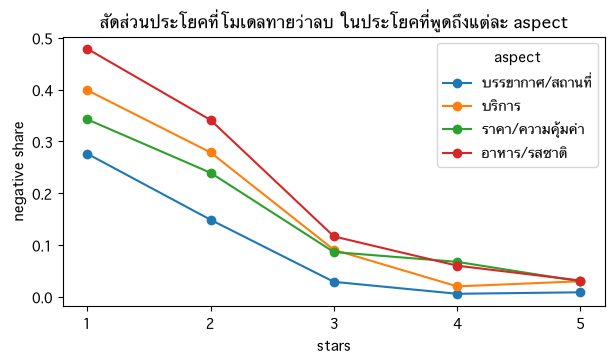

In [13]:
import joblib
from src.cleaner import ThaiTextCleaner
from src.tokenizer import identity_tokenizer  # noqa: F401  (needed to unpickle tfidf)

clf = joblib.load(ROOT / "models" / "sentiment_model.pkl")
tfidf = joblib.load(ROOT / "models" / "tfidf_vectorizer.pkl")
cleaner = ThaiTextCleaner()
sents["p_pos"] = clf.predict_proba(tfidf.transform([" ".join(cleaner.clean(s)) for s in sents.sentence]))[:, 1]

rows = []
for a in ASPECTS:
    hit = sents[sents[f"kw_{a}"] == 1]
    for stars, g in hit.groupby("stars"):
        rows.append({"aspect": ASPECT_NAMES_TH[a], "stars": stars, "negative share": (g.p_pos < 0.5).mean()})
neg = pd.DataFrame(rows).pivot(index="stars", columns="aspect", values="negative share")
neg.plot(marker="o", figsize=(7, 3.5), title="สัดส่วนประโยคที่โมเดลทายว่าลบ ในประโยคที่พูดถึงแต่ละ aspect")
plt.ylabel("negative share"); plt.xticks(range(1, 6))
plt.savefig(FIGS / "aspects_negative_share_preview.png", dpi=120, bbox_inches="tight")
neg.round(2)

In [14]:
# notebook 06 (topics) reuses these sentences; row order matches the cached embeddings
sents.to_parquet(INTERIM / "sentences.parquet")

**อ่านกราฟ:** ในรีวิว 1 ดาว ประโยคเรื่องอาหารถูกทายว่าลบ 48% และบริการ 40% ส่วนรีวิว 4–5 ดาวแทบไม่มีประโยคลบในทุก aspect
ทิศทางสมเหตุสมผล แต่ตัวเลขดูต่ำเกินไป ประโยคในรีวิว 1 ดาวที่พูดเรื่องอาหารควรเป็นลบมากกว่าครึ่ง
เป็นไปได้สองอย่าง: มีประโยคเล่าเรื่องกลางๆ เยอะ หรือ baseline ที่เทรนจากทั้งรีวิวทำงานกับประโยคสั้นได้ไม่ดี
**label ที่เราจะทำจะตอบคำถามนี้ได้** (มีช่อง pos/neg/neu ในแต่ละ aspect)

## 6. สร้างชุด label

**วิธีสุ่ม 400 ประโยค:**
- **200 ประโยคสุ่มแบบสุ่มล้วน:** สะท้อนประโยคจริง (รวมประโยคที่ไม่มี aspect) ใช้วัด **recall** ได้ถูกต้อง คือวิธีไหนพลาดประโยคที่มี aspect ไปเท่าไร
- **200 ประโยคเลือกเพิ่ม (aspect ละ 50):** จากประโยคที่ keyword **หรือ** zero-shot บอกว่ามี aspect นั้น
  เพราะบริการและบรรยากาศอยู่แค่ ~5% ของประโยค ถ้าสุ่มล้วนจะได้ตัวอย่างไม่กี่ประโยค วัด precision ไม่ได้
- ตอนวัดผลต้องแยกสองกลุ่มนี้ (เก็บไว้ใน `sample_group`) เพราะกลุ่มที่เลือกเพิ่ม **ลำเอียง** ไปทางที่สองวิธีนี้เจออยู่แล้ว

**ทำไมไฟล์สำหรับ label ไม่มีคำทายของโมเดล:** ถ้าเห็นว่าโมเดลทาย "ราคา" คนที่ label มีแนวโน้มจะเห็นด้วยตาม
(*anchoring bias*) แล้ว label ก็จะดูเหมือนโมเดลแม่นกว่าความจริง คำทายและกลุ่มการสุ่มจึงแยกไปเก็บไว้ใน `aspect_sentences_meta.csv`

**ไฟล์ถูก freeze:** ถ้ามีไฟล์อยู่แล้ว เซลล์นี้จะไม่สร้างใหม่ เพราะ (1) อาจกำลัง label อยู่ (2) keyword ถูกปรับหลังสุ่มไปแล้ว
ถ้าสุ่มใหม่ด้วย keyword ชุดใหม่จะได้ประโยคคนละชุด คะแนนใน meta (`kw_*`, `zs_*`) จึงเป็นค่า **ตอนสุ่ม** ไม่ใช่ค่าปัจจุบัน

In [15]:
LABEL_FILE, META_FILE = LABELS / "aspect_sentences.csv", LABELS / "aspect_sentences_meta.csv"
FROZEN = LABEL_FILE.exists()   # never regenerate: labeling may be in progress, and keywords may have changed since

if FROZEN:
    meta = pd.read_csv(META_FILE)
    print(f"{LABEL_FILE.name} already exists ({len(meta)} sentences), not regenerating.")
else:
    rng = np.random.default_rng(0)
    N_RANDOM, N_PER_ASPECT = 200, 50

    chosen = set(rng.choice(len(sents), N_RANDOM, replace=False))
    groups = {i: "random" for i in chosen}
    for a in ASPECTS:
        pool = sents.index[(sents[f"kw_{a}"] == 1) | sents[f"zshit_{a}"]].difference(list(chosen))
        pick = rng.choice(pool, N_PER_ASPECT, replace=False)
        chosen |= set(pick)
        groups.update({i: f"enriched_{a}" for i in pick})

    lab = sents.loc[sorted(chosen)].copy()
    lab["sample_group"] = lab.index.map(groups)
    lab = lab.sample(frac=1, random_state=0)   # shuffle so groups are mixed while labeling

    def neighbour(row, offset):
        m = sents[(sents.review_id == row.review_id) & (sents.pos == row.pos + offset)]
        return m.sentence.iloc[0] if len(m) else ""

    lab["context_before"] = [neighbour(r, -1) for r in lab.itertuples()]
    lab["context_after"] = [neighbour(r, +1) for r in lab.itertuples()]
    lab["id"] = range(1, len(lab) + 1)

    to_label = lab[["id", "context_before", "sentence", "context_after"]].assign(**{a: "" for a in ASPECTS}, note="")
    meta = lab[["id", "review_id", "stars", "pos", "sample_group"]
               + [f"kw_{a}" for a in ASPECTS] + [f"zs_{a}" for a in ASPECTS]].round(4)
    to_label.to_csv(LABEL_FILE, index=False, encoding="utf-8-sig")
    meta.to_csv(META_FILE, index=False)
    print(len(to_label), "sentences ->", LABEL_FILE)

meta.sample_group.value_counts()

aspect_sentences.csv already exists (400 sentences), not regenerating.


sample_group
random               200
enriched_price        50
enriched_taste        50
enriched_service      50
enriched_ambience     50
Name: count, dtype: int64

## 7. ถัดไป: label 400 ประโยค

1. เปิด `data/labels/aspect_sentences.csv` ด้วย Google Sheets หรือ Excel
2. อ่านกติกาใน [`docs/aspect_labeling_guide.md`](../docs/aspect_labeling_guide.md) ก่อนเริ่ม
3. ใส่ `pos` / `neg` / `neu` ในคอลัมน์ aspect ที่ประโยคพูดถึง เว้นว่างถ้าไม่พูดถึง (ดู `context_before` / `context_after` ประกอบได้)
4. บันทึกทับไฟล์เดิม (UTF-8 CSV) แล้วส่งกลับมา

ใช้เวลาราว 1.5–2 ชั่วโมง (ประมาณ 15 วินาทีต่อประโยค) แนะนำให้ทำ 50 ประโยคแรกก่อนแล้วกลับไปแก้กติกาถ้าเจอเคสกำกวม
ส่วนที่ 2 จะวัดผล keyword vs zero-shot ด้วย label นี้ แล้วเทรน classifier